# Tabular — Klasifikasi Multikelas
**Kapan dipakai:** seperti klasifikasi biasa, tetapi labelnya lebih dari dua kelas
dan semua feature berupa angka.

**Data demo:** Covertype (target `Cover_Type`, 7 jenis tutupan hutan).
Semua kolom selain `id` dipakai sebagai feature.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/tabular_extra/multiclass"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/covertype_train.csv"
TEST_CSV = f"{DATA_FOLDER}/covertype_test.csv"

TARGET = "Cover_Type"
ID_COL = "id"
SEED = 42

## Baca data
`FEATURES` = semua kolom test kecuali kolom id.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
FEATURES = test.columns.drop(ID_COL).tolist()
print("train:", train.shape, "| test:", test.shape, "|", len(FEATURES), "feature")
missing_per_column = train.isna().sum()
print("sel kosong:", missing_per_column.sum())
train.head()

train: (6000, 56) | test: (2000, 55) | 54 feature
sel kosong: 0


,id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2675,3101.0,359.0,10.0,124.0,6.0,5515.0,205.0,222.0,154.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,tipe_1
1,7287,3012.0,225.0,1.0,30.0,1.0,5102.0,217.0,239.0,159.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,tipe_1
2,3686,3043.0,252.0,18.0,60.0,6.0,2240.0,176.0,249.0,209.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,tipe_2
3,1000,3229.0,192.0,9.0,446.0,29.0,2278.0,220.0,248.0,162.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,tipe_1
4,4798,3203.0,306.0,8.0,134.0,13.0,1390.0,197.0,235.0,178.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,tipe_1


## EDA
Jumlah baris per kelas: kelas kecil biasanya paling sulit ditebak.

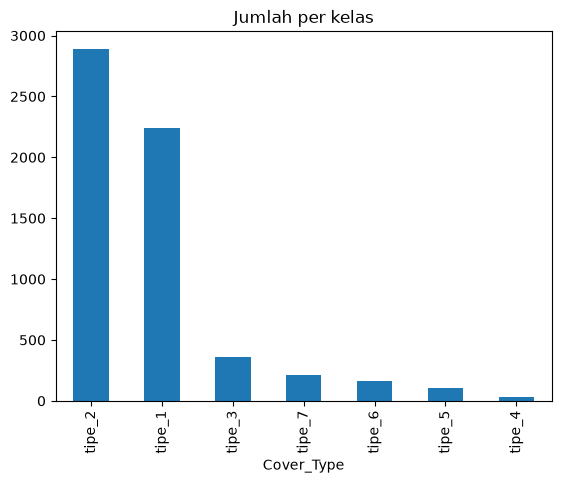

Cover_Type
tipe_1    3134.704464
tipe_2    2925.062608
tipe_3    2398.476323
tipe_4    2177.483871
tipe_5    2780.088235
tipe_6    2410.963190
tipe_7    3372.107477
Name: Elevation, dtype: float64

In [4]:
train[TARGET].value_counts().plot.bar()
plt.title("Jumlah per kelas")
plt.show()
train.groupby(TARGET)["Elevation"].mean()

## Split train / validasi

In [5]:
X = train[FEATURES]
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("train:", X_train.shape, "| validasi:", X_val.shape)

train: (4800, 54) | validasi: (1200, 54)


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
model = LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=SEED, verbose=-1)
# model = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = HistGradientBoostingClassifier(random_state=SEED)
# model = LogisticRegression(C=1.0, max_iter=3000)
# model = KNeighborsClassifier(n_neighbors=5)
# model = SVC(C=1.0, random_state=SEED)
# model = MLPClassifier(hidden_layer_sizes=(128,), max_iter=1000, random_state=SEED)
# model = GaussianNB()
# model = LinearDiscriminantAnalysis()
# model = DecisionTreeClassifier(random_state=SEED)
# model = AdaBoostClassifier(n_estimators=300, random_state=SEED)

pipe = make_pipeline(StandardScaler(), model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lgbmclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['tipe_1','tipe_2','tipe_3',...,'tipe_5','tipe_6','tipe_7']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](54,)","['Elevation','Aspect','Slope',...,'Soil_Type_37','Soil_Type_38', 'Soil_Type_39']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,54
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluasi di validasi

F1 macro: 0.6547
              precision    recall  f1-score   support

      tipe_1       0.81      0.80      0.80       448
      tipe_2       0.81      0.85      0.83       578
      tipe_3       0.75      0.83      0.79        72
      tipe_4       0.67      0.67      0.67         6
      tipe_5       0.50      0.10      0.17        20
      tipe_6       0.65      0.39      0.49        33
      tipe_7       0.84      0.84      0.84        43

    accuracy                           0.80      1200
   macro avg       0.72      0.64      0.65      1200
weighted avg       0.80      0.80      0.80      1200



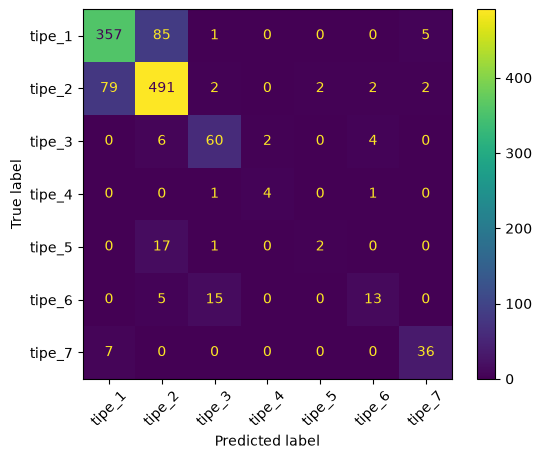

In [7]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=45)
plt.show()

## Latih ulang di semua data + submission

In [8]:
pipe.fit(X, y)
predictions = pipe.predict(test[FEATURES])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["Cover_Type"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,Cover_Type
0,7465,tipe_2
1,3595,tipe_2
2,202,tipe_2
3,6058,tipe_3
4,5658,tipe_1
